In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score)

In [25]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/bank_marketing_20000.csv")

In [26]:
df.head()

,Age,Job,MaritalStatus,Education,AccountBalance,HousingLoan,PersonalLoan,ContactType,CampaignContacts,PreviousContacts,DaysSincePreviousContact,CallDurationSeconds,Subscription
0,49,student,divorced,tertiary,4366.78,yes,no,cellular,6,2,5,704,Yes
1,40,entrepreneur,single,secondary,-98.64,yes,no,cellular,9,1,10,217,No
2,36,technician,married,secondary,3984.59,no,no,cellular,7,0,30,865,No
3,67,admin,divorced,primary,-483.38,yes,no,cellular,3,0,10,769,No
4,38,blue_collar,divorced,tertiary,-1276.58,yes,yes,unknown,5,1,5,543,No


In [27]:
df.shape

(20000, 13)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       20000 non-null  int64  
 1   Job                       20000 non-null  object 
 2   MaritalStatus             20000 non-null  object 
 3   Education                 20000 non-null  object 
 4   AccountBalance            20000 non-null  float64
 5   HousingLoan               20000 non-null  object 
 6   PersonalLoan              20000 non-null  object 
 7   ContactType               20000 non-null  object 
 8   CampaignContacts          20000 non-null  int64  
 9   PreviousContacts          20000 non-null  int64  
 10  DaysSincePreviousContact  20000 non-null  int64  
 11  CallDurationSeconds       20000 non-null  int64  
 12  Subscription              20000 non-null  object 
dtypes: float64(1), int64(5), object(7)
memory usage: 2.0+ MB


In [29]:
df.isnull().sum()

Age                         0
Job                         0
MaritalStatus               0
Education                   0
AccountBalance              0
HousingLoan                 0
PersonalLoan                0
ContactType                 0
CampaignContacts            0
PreviousContacts            0
DaysSincePreviousContact    0
CallDurationSeconds         0
Subscription                0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df.describe()

,Age,AccountBalance,CampaignContacts,PreviousContacts,DaysSincePreviousContact,CallDurationSeconds
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,43.977000,1478.756520,6.507000,1.193100,42.055200,459.047500
std,15.364224,2012.728096,3.457954,1.089895,41.441221,255.194061
min,18.000000,-1500.000000,1.000000,0.000000,-1.000000,20.000000
25%,31.000000,-88.282500,3.000000,0.000000,10.000000,236.000000
50%,44.000000,1382.665000,7.000000,1.000000,30.000000,462.000000
75%,57.000000,2856.457500,10.000000,2.000000,90.000000,678.000000
max,70.000000,10130.380000,12.000000,7.000000,120.000000,899.000000


In [32]:
df.columns

Index(['Age', 'Job', 'MaritalStatus', 'Education', 'AccountBalance',
       'HousingLoan', 'PersonalLoan', 'ContactType', 'CampaignContacts',
       'PreviousContacts', 'DaysSincePreviousContact', 'CallDurationSeconds',
       'Subscription'],
      dtype='object')

In [33]:
df.head()

,Age,Job,MaritalStatus,Education,AccountBalance,HousingLoan,PersonalLoan,ContactType,CampaignContacts,PreviousContacts,DaysSincePreviousContact,CallDurationSeconds,Subscription
0,49,student,divorced,tertiary,4366.78,yes,no,cellular,6,2,5,704,Yes
1,40,entrepreneur,single,secondary,-98.64,yes,no,cellular,9,1,10,217,No
2,36,technician,married,secondary,3984.59,no,no,cellular,7,0,30,865,No
3,67,admin,divorced,primary,-483.38,yes,no,cellular,3,0,10,769,No
4,38,blue_collar,divorced,tertiary,-1276.58,yes,yes,unknown,5,1,5,543,No


In [34]:
from sklearn.preprocessing import LabelEncoder

In [35]:
X=df.drop(columns="Subscription",axis=1)
y=df["Subscription"]

In [36]:
le = LabelEncoder()
y = le.fit_transform(y)
print("Classes:", le.classes_)
print(dict(zip(le.classes_, le.transform(le.classes_))))

Classes: ['No' 'Yes']
{'No': np.int64(0), 'Yes': np.int64(1)}


# Identify Numerical and Categorical Columns

In [37]:
numerical_cal=X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_cal=X.select_dtypes(include=["object"]).columns.tolist()

# Train-Test Split

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16000, 12)
Testing data: (4000, 12)


In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cal),

        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cal)])

In [43]:
ada_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        random_state=42
    ))
])

In [44]:
ada_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Age','Job','MaritalStatus',...,'PreviousContacts', 'DaysSincePreviousContact','CallDurationSeconds']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyi

In [45]:
y_pred = ada_model.predict(X_test)
y_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [46]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.79025


In [47]:
print("Recall:", recall_score(y_test, y_pred))

Recall: 0.08649289099526067


In [48]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=le.classes_))

              precision    recall  f1-score   support

          No       0.80      0.98      0.88      3156
         Yes       0.52      0.09      0.15       844

    accuracy                           0.79      4000
   macro avg       0.66      0.53      0.51      4000
weighted avg       0.74      0.79      0.73      4000



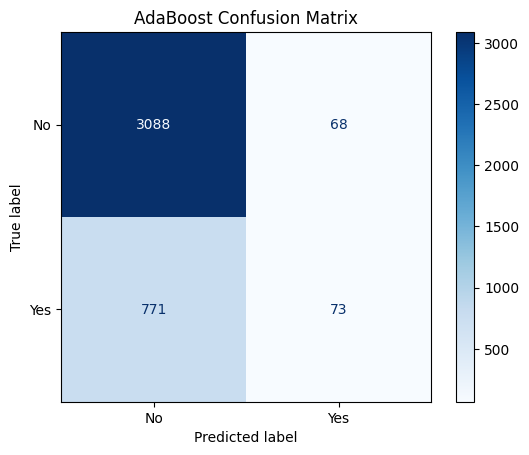

In [49]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_)

disp.plot(cmap="Blues")
plt.title("AdaBoost Confusion Matrix")
plt.show()

In [50]:
y_prob = ada_model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.6856375278563662


In [51]:
param_dist = {
    "classifier__n_estimators": [50, 100, 150, 200, 300],

    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],

    "classifier__estimator__max_depth": [1, 2, 3, 4],

    "classifier__estimator__min_samples_split": [2, 5, 10],

    "classifier__estimator__min_samples_leaf": [1, 2, 4]}

In [52]:
random_search = RandomizedSearchCV(
    estimator=ada_model,
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__estimator__max_depth': [1, 2, ...], 'classifier__estimator__min_samples_leaf': [1, 2, ...], 'classifier__estimator__min_samples_split': [2, 5, ...], 'classifier__learning_rate': [0.01, 0.05, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum

In [53]:
print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'classifier__n_estimators': 300, 'classifier__learning_rate': 1.0, 'classifier__estimator__min_samples_split': 10, 'classifier__estimator__min_samples_leaf': 1, 'classifier__estimator__max_depth': 2}


In [54]:
print("Best CV F1 Score:", random_search.best_score_)

Best CV F1 Score: 0.15592196064595573


In [55]:
best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_best))

print("Precision:", precision_score(y_test, y_pred_best))

print("Recall:", recall_score(y_test, y_pred_best))

print("F1 Score:", f1_score(y_test, y_pred_best))

Accuracy: 0.7905
Precision: 0.51875
Recall: 0.09834123222748815
F1 Score: 0.16533864541832669


In [56]:
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=le.classes_))

              precision    recall  f1-score   support

          No       0.80      0.98      0.88      3156
         Yes       0.52      0.10      0.17       844

    accuracy                           0.79      4000
   macro avg       0.66      0.54      0.52      4000
weighted avg       0.74      0.79      0.73      4000



In [57]:
best_params = random_search.best_params_
param_grid = {
    "classifier__n_estimators": [
        best_params["classifier__n_estimators"]
    ],

    "classifier__learning_rate": [
        best_params["classifier__learning_rate"]
    ],

    "classifier__estimator__max_depth": [
        best_params["classifier__estimator__max_depth"]
    ],

    "classifier__estimator__min_samples_split": [
        best_params["classifier__estimator__min_samples_split"]
    ],

    "classifier__estimator__min_samples_leaf": [
        best_params["classifier__estimator__min_samples_leaf"]
    ]
}

In [58]:
grid_search = GridSearchCV(
    estimator=ada_model,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 1 candidates, totalling 3 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__estimator__max_depth': [2], 'classifier__estimator__min_samples_leaf': [1], 'classifier__estimator__min_samples_split': [10], 'classifier__learning_rate': [1.0], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about

In [59]:
print("Best Grid Parameters:", grid_search.best_params_)
print("Best Grid Score:", grid_search.best_score_)

Best Grid Parameters: {'classifier__estimator__max_depth': 2, 'classifier__estimator__min_samples_leaf': 1, 'classifier__estimator__min_samples_split': 10, 'classifier__learning_rate': 1.0, 'classifier__n_estimators': 300}
Best Grid Score: 0.15592196064595573


In [60]:
final_model = grid_search.best_estimator_
final_pred = final_model.predict(X_test)
print("Final Accuracy:", accuracy_score(y_test, final_pred))
print("Final Precision:", precision_score(y_test, final_pred))
print("Final Recall:", recall_score(y_test, final_pred))
print("Final F1 Score:", f1_score(y_test, final_pred))

Final Accuracy: 0.7905
Final Precision: 0.51875
Final Recall: 0.09834123222748815
Final F1 Score: 0.16533864541832669


In [61]:
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = final_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
5,num__CallDurationSeconds,0.323786
1,num__AccountBalance,0.271519
2,num__CampaignContacts,0.159121
0,num__Age,0.093850
21,cat__HousingLoan_yes,0.032739
20,cat__HousingLoan_no,0.028099
3,num__PreviousContacts,0.024983
12,cat__Job_student,0.012264
4,num__DaysSincePreviousContact,0.010681
19,cat__Education_tertiary,0.010392


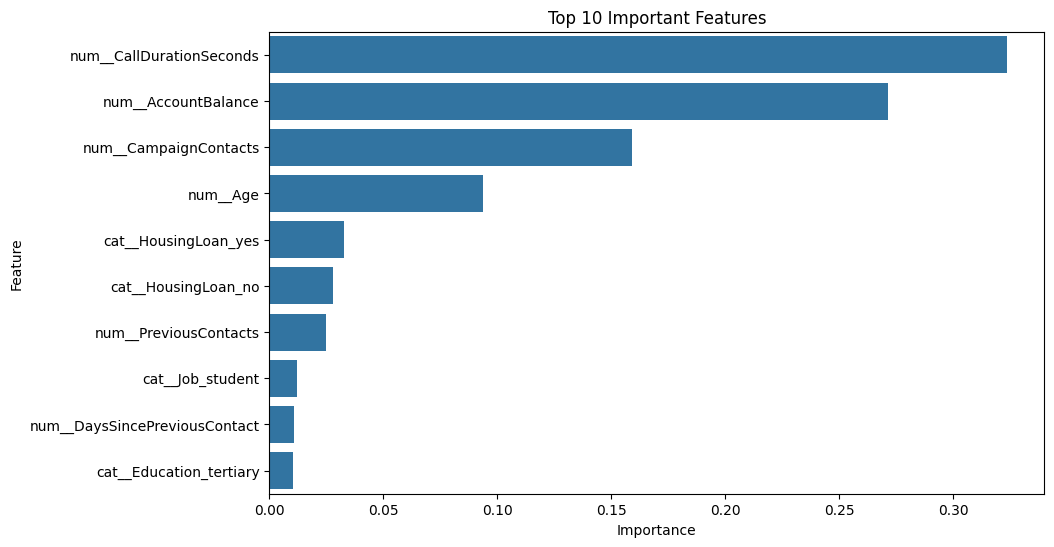

In [62]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")

plt.show()

In [63]:
new_customer = pd.DataFrame([{
    "Age": 35,
    "Job": "management",
    "MaritalStatus": "married",
    "Education": "tertiary",
    "AccountBalance": 2500,
    "HousingLoan": "no",
    "PersonalLoan": "no",
    "ContactType": "cellular",
    "CampaignContacts": 2,
    "PreviousContacts": 1,
    "DaysSincePreviousContact": 30,
    "CallDurationSeconds": 300
}])

In [64]:
prediction = final_model.predict(new_customer)
predicted_result = le.inverse_transform(prediction)
print("Bank Subscription Prediction:", predicted_result[0])

Bank Subscription Prediction: No


In [65]:
joblib.dump(final_model, "bank_marketing_model.pkl")
joblib.dump(le, "subscription_label_encoder.pkl")
print("Model Saved Successfully!")

Model Saved Successfully!


In [66]:
loaded_model = joblib.load("bank_marketing_model.pkl")
loaded_encoder = joblib.load("subscription_label_encoder.pkl")

In [67]:
prediction = loaded_model.predict(new_customer)
result = loaded_encoder.inverse_transform(prediction)
print("Predicted Subscription:", result[0])

Predicted Subscription: No
